# AAIL Session 3: First Contact With Data

📎 **Slides:** [Session 3 slides](https://docs.google.com/presentation/d/14wE5-nPuI97KfS8ZJrnIQhuwkroiTQL6Bhcjmwvxejs/view)

**⚠️ First: File → Save a copy in Drive.** Otherwise your work won't be saved. Keep this copy: the `X` and `y` you build today go into your first model.

---

**How to use this notebook:** click a code cell and press **Shift + Enter** to run it. Text cells marked ✏️ are for your answers: **double-click to type in them.**

The notebook has two blocks. Work on **Block A** after the first lecture and **Block B** after the second. Click the arrow next to a block's title to collapse it.

Each block ends with an optional challenge. **Most people will not get the challenges.** If you finish early, go for it.

# Block A: Loading and Looking at Data

## A1: Load the data

Load the songs dataset from url into a variable called `df`, then show how many rows and columns it has.

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/aail-club/notebooks/main/data/s3_songs.csv"

# load the data from url into a variable called df
df = pd.read_csv(url)
# show how many rows and columns df has
df.shape

(300, 6)

✏️ **How many rows? How many columns?**

## A2: Look at the first rows

In [3]:
df.head()

,title,tempo,energy,danceability,duration_s,genre
0,Track 001,108,0.44,0.76,185,pop
1,Track 002,128,0.94,0.75,241,edm
2,Track 003,130,0.95,0.84,216,edm
3,Track 004,148,0.32,0.53,309,jazz
4,Track 005,136,0.66,0.75,204,pop


✏️ **Pick one column. What does it measure?**

## A3: Fix the broken cell

This cell is supposed to show the number of rows and columns. Run it, read the error, and fix it.

In [ ]:
df.shape

✏️ **In one sentence: why did it break?**

## A4: Summarize every number column

In [5]:
df.describe()

,tempo,energy,danceability,duration_s
count,300.000000,286.000000,300.000000,300.000000
mean,106.883333,0.659091,0.714367,212.320000
std,22.160777,0.161101,0.103144,40.396665
min,0.000000,0.180000,0.360000,95.000000
25%,92.750000,0.572500,0.650000,190.000000
50%,109.000000,0.665000,0.720000,208.000000
75%,124.000000,0.770000,0.792500,228.000000
max,163.000000,0.980000,0.950000,409.000000


✏️ **Which column has missing values? How can you tell from this table?**

## ⚡ Block A Challenge (optional, and most people will not get it)

Look closely at the **`min`** row of `df.describe()`.

✏️ **One column has a minimum value that no real song could have. Which column, and what do you think that value really means?**


✏️ **Will `df.dropna()` remove those rows? Explain why or why not, and why that's dangerous.**


🏆 **Solved it?** Share your notebook with **woottonaail@gmail.com** (Share button, top right). We'll add it to your challenge tally!

# Block B: Features, Labels, and Cleaning

## B1: Build X and y

We want to predict a song's **genre** from its **tempo** and **energy**.

Make `y` (the label) and `X` (the features), then show the shape of each.

In [8]:
# y: the genre column
y=df["genre"]
# X: the tempo and energy columns
X=df[["genre", "energy"]]
# show the shape of X and the shape of y (use print() for both)
print(X.shape)
print(y.shape)

(300, 2)
(300,)


✏️ **`X.shape` has two numbers but `y.shape` has only one. Why?**

## B2: Check class balance

In [10]:
# count how many songs there are of each genre
y.value_counts()

,count
genre,
pop,110
hip-hop,70
edm,55
r&b,45
jazz,20


✏️ **Imagine a lazy model that ignores tempo and energy and always guesses the most common genre. What percent of songs would it get right?** Use the cell below as a calculator.

In [12]:
# calculator
110/300

0.36666666666666664

## B3: Drop missing rows

In [13]:
# drop the rows with missing values (remember the df = part!)
df = df.dropna()
# check df.shape again
df.shape

(286, 6)

✏️ **How many rows were dropped?**


Now run this cell:

In [15]:
# fix X and y so they match the cleaned df
X=df["genre"]
y=df[["tempo", "energy"]]

print(X.shape)
print(y.shape)

(286,)
(286, 2)


✏️ **`df` lost rows, but `X` didn't. Why not?** Then fix it in the cell above.

## B4: Plot it

✏️ **Before you run the plot:** which genre do you think is **fast and high energy**?

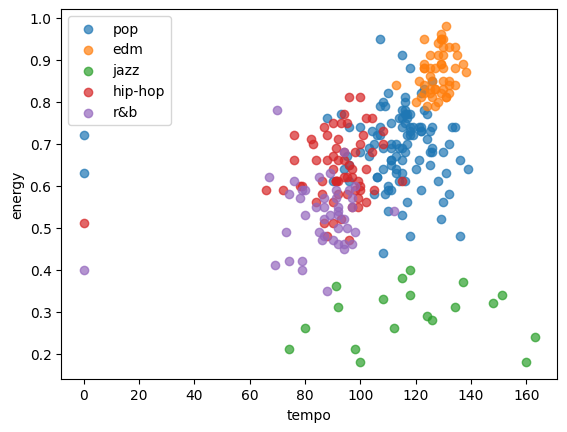

In [16]:
# You don't need to understand this cell yet. Just run it.
import matplotlib.pyplot as plt

x_feature = "tempo"
y_feature = "energy"

for genre in df["genre"].unique():
    songs_in_genre = df[df["genre"] == genre]
    plt.scatter(songs_in_genre[x_feature], songs_in_genre[y_feature], label=genre, alpha=0.7)

plt.xlabel(x_feature)
plt.ylabel(y_feature)
plt.legend()
plt.show()

✏️ **Were you right? Which two genres overlap the most?**

## ⚡ Block B Challenge (optional, and most people will not get it)

In the tempo vs. energy plot, **hip-hop** and **r&b** are mixed together. Tempo and energy alone can't tell them apart.

The dataset has two more number columns: **`danceability`** and **`duration_s`**. In the plot cell, change `x_feature` and `y_feature` to try other pairs.

✏️ **Which pair of features best separates hip-hop from r&b? What does that tell you about choosing features?**


✏️ **Is there a genre that is easy to spot with *any* pair? Which feature makes it stand out?**


🏆 **Solved it?** Share your notebook with **woottonaail@gmail.com** (Share button, top right). We'll add it to your challenge tally! *If you already shared after Block A, you're all set.*

---
## 📝 Before you leave: 1-minute feedback

Tell us how today went: [AAIL Feedback Form](https://docs.google.com/forms/d/1jvALCTM0uQRNQ5jpQvl6mfmRD3s6gQQRAVrfMXztT6c/viewform)

It's anonymous, takes under a minute, and we read every response. Please put 3 for the Session #.